In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import healpy as hp
from astropy.io import fits

sys.path.insert(0, '/work2/08811/aew492/frontera/lss-dipoles/code')
import tools

In [3]:
zodidir = '/work2/08811/aew492/frontera/lss-dipoles/data/maps/zodi'

In [4]:
# load the first map
fn1 = os.path.join(zodidir, 'map_zodi1.25_NSIDE64.npy')
map1 = np.load(fn1)

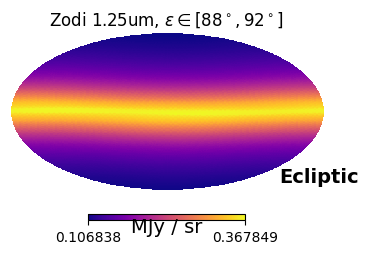

In [5]:
# plot
hp.mollview(map1, coord=['E'], unit='MJy / sr',
            title=r'Zodi 1.25um, $\varepsilon\in[88^\circ,92^\circ]$',
            cmap='plasma', sub=(1,2,1))

In [6]:
# load the second map
fn2 = os.path.join(zodidir, 'zodimap_45.0deg-135.0degfromSun_oneyear_1.25um.fits')
hdu = fits.open(fn2)
print(hdu.info())
hdr = hdu[0].header
print(repr(hdr))
map2 = hdu[0].data

Filename: /work2/08811/aew492/frontera/lss-dipoles/data/maps/zodi/zodimap_45.0deg-135.0degfromSun_oneyear_1.25um.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      13   (49152,)   float64   
None
SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -64 / array data type                                
NAXIS   =                    1 / number of array dimensions                     
NAXIS1  =                49152                                                  
EXTEND  =                    T                                                  
UNIT    = 'MJy / sr'           / Zodi intensity unit                            
WL      =                 1.25 / Observation wavelength (um)                    
MINEPS  =                 45.0 / Min. solar elongation angle observed (deg)     
MAXEPS  =                135.0 / Max. solar elongation angle observed (deg)     
NSIDE   =             

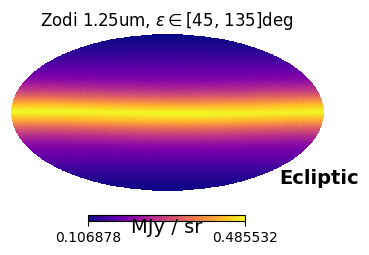

In [7]:
# plot
hp.mollview(map2, coord=['E'], unit=hdr['UNIT'],
            title=f"Zodi {hdr['WL']:.2f}um, "r"$\varepsilon\in$"f"[{hdr['MINEPS']:.0f}, {hdr['MAXEPS']:.0f}]deg",
            cmap='plasma', sub=(1,2,1))

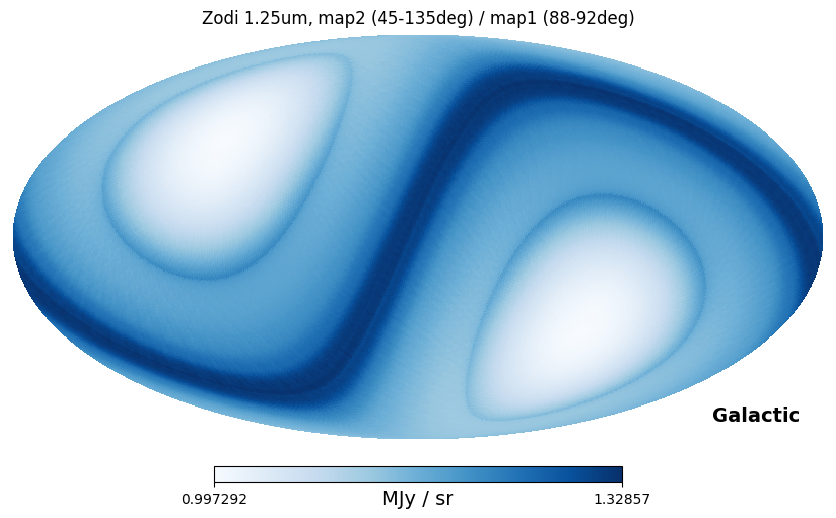

In [8]:
# compare these shapes
hp.mollview(map2 / map1, coord=['E', 'G'], unit=hdr['UNIT'],
            title=f"Zodi {hdr['WL']:.2f}um, map2 (45-135deg) / map1 (88-92deg)", cmap='Blues')

In [9]:
# convert the map to celestial
r = hp.Rotator(coord=['E', 'C'])
map2_celestial = r.rotate_map_pixel(map2)

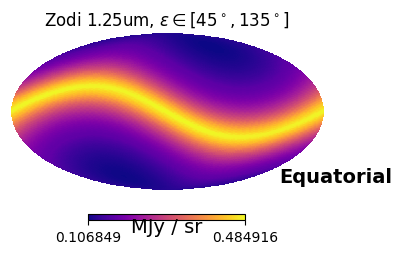

In [11]:
hp.mollview(map2_celestial, coord=['C'], unit='MJy / sr',
            title=r'Zodi 1.25um, $\varepsilon\in[45^\circ,135^\circ]$',
            cmap='plasma', sub=(1,2,1))

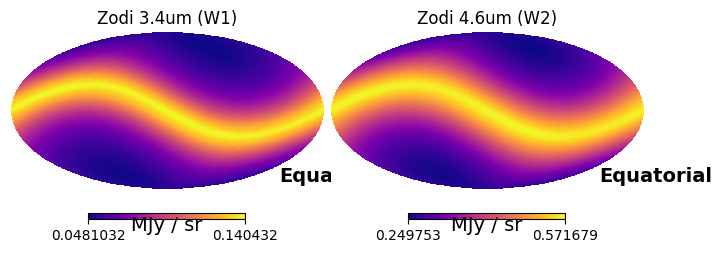

In [14]:
# same thing with the W1 and W2 maps
maps_wise_celestial = []
for i, (wl, label) in enumerate(zip([3.4, 4.6], ['W1', 'W2'])):
    fn = os.path.join(zodidir, f'map_zodi{wl:.1f}_NSIDE64.npy')
    map_wise = np.load(fn)
    map_wise_celestial = r.rotate_map_pixel(map_wise)
    hp.mollview(map_wise_celestial, coord=['C'], unit='MJy / sr',
                title=f'Zodi {wl:.1f}um ({label})', cmap='plasma', sub=(1,2,i+1))
    np.save(os.path.join(zodidir, f'zodimap_88-92degfromSun_oneyear_{wl:.1f}um_celestial.npy'), map_wise_celestial)